# Hospital Emergency Energy Management - Optimization Model

---

**Authors:** Jorge Carrnicero, Liam Esgueva, Andrés Gil, Jorge González

This notebook implements a goal-programming optimization model to manage hospital services during a blackout using existing generators and optional candidate generators. 


### Importing packages and modules

In [1]:
# module for building the pyomo model
import pyomo.environ as pe
# module for solving the pyomo model
import pyomo.opt as po
import warnings
warnings.filterwarnings('ignore')

### Create the model

In [2]:
model = pe.ConcreteModel()

In [3]:
# Scenario Configuration
BLACKOUT_DURATION = 24
BUDGET = 20000
LAMBDA_1 = 0.5  # Utility
LAMBDA_2 = 1 - LAMBDA_1  # Equity

Order to build the model:
1. Sets
1. Parameters
1. Variables
1. Objective function
1. Constraints


---

#### Sets

$T$: Time periods $\{1, ..., 48\}$ (Hours)

$S$: Hospital Services $\{UCI, OperatingRoom, ...\}$

$S_{crit} \subset S$: Critical Services

$G$: All generator types $\{Large, Medium, Small\}$

$G_{cand} \subseteq G$: Candidate generator types available for purchase

In [4]:
# Sets Definition
model.T = pe.Set(initialize=list(range(1, BLACKOUT_DURATION + 1)))
model.G = pe.Set(initialize=['Large', 'Medium', 'Small'])
model.S = pe.Set(initialize=['UCI', 'OperatingRoom', 'ER', 'Lab', 'Pharmacy', 'Admin'])
model.S_crit = pe.Set(initialize=['UCI', 'OperatingRoom', 'ER'])

---

#### Parameters

**Economic & Technical Constants**

$Budget$: Total investment budget available [$].

$Cost_g$: Cost per unit of generator type $g$ [$].

$P^{max}_g$: Max power per unit [kW].

$E^{max}_g$: Fuel capacity per unit [kWh].

$N^{exist}_g$: Number of units already owned.

In [5]:
# Global Constants
model.budget = pe.Param(initialize=BUDGET)

# Generator Specs (Per Unit)
fuel_capacity = {'Large': 500, 'Medium': 150, 'Small': 60}
max_power =     {'Large': 250,  'Medium': 75,  'Small': 30}
unit_cost =     {'Large': 55000,'Medium': 27000,'Small': 15000}

# Existing Inventory
existing_inventory = {'Large': 1, 'Medium': 1, 'Small': 1}
existing_fuel_initial = {'Large': 500, 'Medium': 150, 'Small': 60}

# Assigning to Model
model.E_max = pe.Param(model.G, initialize=fuel_capacity)
model.P_max = pe.Param(model.G, initialize=max_power)
model.Cost = pe.Param(model.G, initialize=unit_cost)
model.N_exist = pe.Param(model.G, initialize=existing_inventory)
model.E_initial = pe.Param(model.G, initialize=existing_fuel_initial)

**Service Demand & Priorities**

$Dem_s$: Power demand of service $s$ [kW].

$W_s$: Importance/Criticality weight.

In [6]:
consumption = {'UCI': 30, 'OperatingRoom': 35, 'ER': 25, 'Lab': 15, 'Pharmacy': 10, 'Admin': 5}
importance = {'UCI': 100, 'OperatingRoom': 85, 'ER': 70, 'Lab': 30, 'Pharmacy': 15, 'Admin': 5}

model.Dem_s = pe.Param(model.S, initialize=consumption)
model.W_s = pe.Param(model.S, initialize=importance)

**Goal Programming Config**

$\lambda_1, \lambda_2$: Weights for Utility and Equity.

$K$: Normalization factor for Maximin.

$\alpha$: Urgency decay rate.

In [7]:
MAX_GAP = 0.20 
MIN_LEVEL = 0.10 
RESIDUAL_FINAL_VALUE = 0.05

if BLACKOUT_DURATION > 1:
    URGENCY_RATE = (1 / RESIDUAL_FINAL_VALUE)**(1 / (BLACKOUT_DURATION - 1)) - 1
else:
    URGENCY_RATE = 0

max_pts = sum(importance.values()) * sum(1 / ((1 + URGENCY_RATE)**(t - 1)) for t in range(1, BLACKOUT_DURATION+1))
max_min_val = 1 / max(importance.values())
FACTOR_K = max_pts / max_min_val 

model.lam1 = pe.Param(initialize=LAMBDA_1)
model.lam2 = pe.Param(initialize=LAMBDA_2)
model.k_factor = pe.Param(initialize=FACTOR_K)
model.max_gap = pe.Param(initialize=MAX_GAP)

---

#### Variables

$z^{inv}_g$: Number of new units of type $g$ purchased (Integer).

$a_{g,t}$: Number of active units of type $g$ at time $t$ (Integer).

$u_{g,t}$: Energy generated by type $g$ at time $t$ (Continuous).

$x_{s,t}$: Service level fraction $\in [0,1]$.

$s_{g,t}$: Start up variable for the generators.

$z^{min}$: Maximin auxiliary variable.

In [8]:
model.z_inv = pe.Var(model.G, within=pe.NonNegativeIntegers)
model.a = pe.Var(model.G, model.T, within=pe.NonNegativeIntegers)
model.u = pe.Var(model.G, model.T, within=pe.NonNegativeReals)
model.x = pe.Var(model.S, model.T, bounds=(0,1))
model.y = pe.Var(model.T, within=pe.Binary)
model.z_min = pe.Var(within=pe.NonNegativeReals)
model.start = pe.Var(model.G, model.T, within=pe.NonNegativeIntegers)

---

#### Objective Function

Maximize weighted sum of Total Utility ($G_1$) and Equity ($G_2$).

$Max \ Z = \lambda_1 \sum_t \sum_s \frac{W_s \cdot x_{s,t}}{(1+\alpha)^{t-1}} + \lambda_2 \cdot K \cdot z^{min}$

In [9]:
def objective_rule(m):
    score_util = 0
    for t in m.T:
        time_factor = 1 / ((1 + URGENCY_RATE)**(t - 1))
        util = sum(m.W_s[s] * m.x[s,t] for s in m.S)
        score_util += util * time_factor
    
    score_equity = m.z_min * m.k_factor
    
    return (m.lam1 * score_util) + (m.lam2 * score_equity)

model.objective = pe.Objective(rule=objective_rule, sense=pe.maximize)

---

#### Constraints

Constraint #1: Hard Budget Limit

$\sum_g (Cost_g \cdot z^{inv}_g) \le Budget$

In [10]:
def budget_rule(m):
    return sum(m.Cost[g] * m.z_inv[g] for g in m.G) <= m.budget

model.c_budget = pe.Constraint(rule=budget_rule)

Constraint #2: Availability & Power

Active units cannot exceed total inventory: $a_{g,t} \le N^{exist}_g + z^{inv}_g$

Power output limited by active units: $u_{g,t} \le P^{max}_g \cdot a_{g,t}$

In [11]:
def availability_rule(m, g, t):
    return m.a[g,t] <= m.N_exist[g] + m.z_inv[g]
model.c_availability = pe.Constraint(model.G, model.T, rule=availability_rule)

def power_rule(m, g, t):
    return m.u[g,t] <= m.P_max[g] * m.a[g,t]
model.c_power = pe.Constraint(model.G, model.T, rule=power_rule)

Constraint #3: Fuel Tank Capacity

Total energy generated cannot exceed initial fuel + fuel from new units.

$\sum_t u_{g,t} \le (E^{initial}_g \cdot N^{exist}_g) + (E^{max}_g \cdot z^{inv}_g)$

In [12]:
def fuel_rule(m, g):
    total_existing_capacity = m.E_initial[g] * m.N_exist[g]
    total_new_capacity = m.E_max[g] * m.z_inv[g]
    return sum(m.u[g,t] for t in m.T) <= total_existing_capacity + total_new_capacity

model.c_fuel = pe.Constraint(model.G, rule=fuel_rule)

Constraint #4: Energy Balance & Service Quality

* Supply = Demand
* Min Level ($y_t$ link)
* Continuity (Monotonic decrease)
* Maximin ($z^{min}$ definition)
* Gap Control (Solidarity among critical services)

In [13]:
# Balance
model.c_balance = pe.Constraint(model.T, 
    rule=lambda m, t: sum(m.u[g,t] for g in m.G) == sum(m.Dem_s[s] * m.x[s,t] for s in m.S))

# Min Level
model.c_y_link = pe.Constraint(model.S, model.T, 
    rule=lambda m, s, t: m.x[s,t] >= m.y[t] * MIN_LEVEL if s in m.S_crit else pe.Constraint.Skip)

# Continuity
model.c_continuity = pe.Constraint(model.S, model.T, 
    rule=lambda m, s, t: m.x[s,t] <= m.x[s,t-1] if (t>1 and s in m.S_crit) else pe.Constraint.Skip)

# Maximin Definition
model.c_maximin = pe.Constraint(model.S, model.T, 
    rule=lambda m, s, t: m.z_min <= m.x[s,t] / m.W_s[s])

# Gap Control
model.c_equity_gap = pe.Constraint(model.S, model.S, model.T, 
    rule=lambda m, s1, s2, t: m.x[s1, t] - m.x[s2, t] <= m.max_gap 
    if (s1 in m.S_crit and s2 in m.S_crit) else pe.Constraint.Skip)

# Start Logic (Aux)
model.c_def_start = pe.Constraint(model.G, model.T, 
    rule=lambda m, g, t: m.start[g,t] >= m.a[g,t] - (m.a[g,t-1] if t>1 else 0))

model.c_limit_starts = pe.Constraint(model.G, 
    rule=lambda m, g: sum(m.start[g,t] for t in m.T) <= 5)

#### Solver definition and solve statement

In [14]:
# HiGHS is free (pip install highspy); Gurobi is used instead if it is installed and licensed.
solver = po.SolverFactory('gurobi')
if solver.available(exception_flag=False):
    solver.options['TimeLimit'] = 120
else:
    solver = po.SolverFactory('appsi_highs')
    solver.options['time_limit'] = 120
results = solver.solve(model, tee=True)


Set parameter Username
Set parameter LicenseID to value 2704583
Academic license - for non-commercial use only - expires 2026-09-08
Read LP format model from file C:\Temp\Win\tmppj_r5y6f.pyomo.lp
Reading time = 0.01 seconds
x1: 748 rows, 389 columns, 1725 nonzeros
Set parameter TimeLimit to value 120
Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (win64 - Windows 10.0 (19045.2))

CPU model: AMD Ryzen 7 5700U with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 8 physical cores, 16 logical processors, using up to 16 threads

Non-default parameters:
TimeLimit  120

Optimize a model with 748 rows, 389 columns and 1725 nonzeros
Model fingerprint: 0x4a23eab6
Variable types: 218 continuous, 171 integer (24 binary)
Coefficient statistics:
  Matrix range     [1e-02, 6e+04]
  Objective range  [1e-01, 1e+05]
  Bounds range     [1e+00, 1e+00]
  RHS range        [2e-01, 2e+04]
Found heuristic solution: objective -0.0000000
Presolve removed 220 rows and 31 columns
Presolve time: 0.

---

### Results Analysis

In [15]:
print("\n" + "="*120)
print(f"DASHBOARD: MULTI-UNIT INVESTMENT (${BUDGET:,.0f})")
print("="*120)

print("\nSHOPPING CART")
print("   " + "-"*60)
total_spent = 0
for g in model.G:
    purchased = int(pe.value(model.z_inv[g]))
    cost = model.Cost[g]
    total_spent += purchased * cost
    print(f"   [TYPE] {g:6} (${cost:,.0f}/u) -> {purchased} units purchased.")

print("   " + "-"*60)
print(f"   TOTAL SPENT: ${total_spent:,.0f} / ${BUDGET:,.0f} ({total_spent/BUDGET*100:.1f}%)")

print("\nPERFORMANCE")
hours_survived = sum(pe.value(model.y[t]) for t in model.T)
print(f"   Survival: {int(hours_survived)} Hours")
print(f"   Equity Index: {pe.value(model.z_min):.4f}")

print("\n" + "-"*120)
print("FLEET STATUS")
print(f"   {'TYPE':12} | {'OWNED (Exist+New)':17} | {'FUEL CAPACITY':19} | {'MAX POWER'} ")
for g in model.G:
    n_total = int(model.N_exist[g] + pe.value(model.z_inv[g]))
    cap_total = (model.E_initial[g]*model.N_exist[g]) + (model.E_max[g]*pe.value(model.z_inv[g]))
    pow_total = model.P_max[g] * n_total
    used = sum(pe.value(model.u[g,t]) for t in model.T)
    print(f"   {g:12} | {n_total} ({model.N_exist[g]} + {int(pe.value(model.z_inv[g]))}){' ':9} | {int(cap_total - used)} / {int(cap_total)} kWh     | {pow_total} kW (Total)")

print("-"*120)
print("SERVICE LEVELS (Snapshot T=48)")
for s in model.S_crit:
    val = pe.value(model.x[s, BLACKOUT_DURATION]) * 100
    print(f"   {s:13} : {int(val)}%")
print("="*120)

# --- VISUAL DASHBOARD ---
print("\n" + "-"*120)
print("GENERATOR USAGE")
for g in model.G:
    n_total = int(model.N_exist[g] + pe.value(model.z_inv[g]))
    # To make bars comparable, we look at total capacity available
    cap_total = (model.E_initial[g]*model.N_exist[g]) + (model.E_max[g]*pe.value(model.z_inv[g]))
    used = sum(pe.value(model.u[g,t]) for t in model.T)
    remaining = cap_total - used
    pct = (remaining / cap_total) * 100 if cap_total > 0 else 0
    bar_len = int(pct / 5)
    bar = "█" * bar_len + "░" * (20 - bar_len)
    print(f"   {g:12} |{bar}| Remaining: {remaining:6.1f} / {cap_total} kWh ({pct:5.1f}%)")
print("-"*120)

# SERVICES
show_limit = 48
header = "              " + " ".join([f"{t:02}" for t in model.T if t <= show_limit])
print("SERVICE LEVEL (%)")
print(f"      {header} ...")

sorted_crit = sorted(model.S_crit, key=lambda s: model.W_s[s], reverse=True)
all_services = sorted_crit + [s for s in model.S if s not in model.S_crit]

for s in all_services:
    if s in model.S_crit:
        imp = int(model.W_s[s])
        name_fmt = f"{s} ({imp})"
    else:
        name_fmt = f"   {s}"
        
    row_str = f"{name_fmt:>16} |"
    for t in model.T:
        val = pe.value(model.x[s,t])
        if t <= show_limit:
            if val > 0.99: row_str += " ✅"
            elif val < 0.005: row_str += "  ."
            else: row_str += f" {int(val*100):2}"
    
    hours = sum(1 for t in model.T if pe.value(model.x[s,t]) >= 0.001)
    print(f"{row_str} | Active: {hours}h")

# CONSUMPTION
print("-"*120)
print("CONSUMPTION (kW) |", end="")
total_acc = 0
for t in model.T:
    demanda = sum(model.Dem_s[s] * pe.value(model.x[s,t]) for s in model.S)
    total_acc += demanda
    if t <= show_limit:
        print(f" {demanda:4.1f}", end="")
print(f" ... | Total Used: {total_acc:.2f} kWh")
print("="*120)


DASHBOARD: MULTI-UNIT INVESTMENT ($20,000)

SHOPPING CART
   ------------------------------------------------------------
   [TYPE] Large  ($55,000/u) -> 0 units purchased.
   [TYPE] Medium ($27,000/u) -> 0 units purchased.
   [TYPE] Small  ($15,000/u) -> 1 units purchased.
   ------------------------------------------------------------
   TOTAL SPENT: $15,000 / $20,000 (75.0%)

PERFORMANCE
   Survival: 0 Hours
   Equity Index: 0.0028

------------------------------------------------------------------------------------------------------------------------
FLEET STATUS
   TYPE         | OWNED (Exist+New) | FUEL CAPACITY       | MAX POWER 
   Large        | 1 (1 + 0)          | 0 / 500 kWh     | 250 kW (Total)
   Medium       | 1 (1 + 0)          | 0 / 150 kWh     | 75 kW (Total)
   Small        | 2 (1 + 1)          | 0 / 120 kWh     | 60 kW (Total)
------------------------------------------------------------------------------------------------------------------------
SERVICE LEVELS (Sna

# GRAPHICS

📁 Guardando gráficos con base: lambda0.5_24hours_budget20000
✅ SCADA guardado: graphics\lambda0.5_24hours_budget20000_scada.png


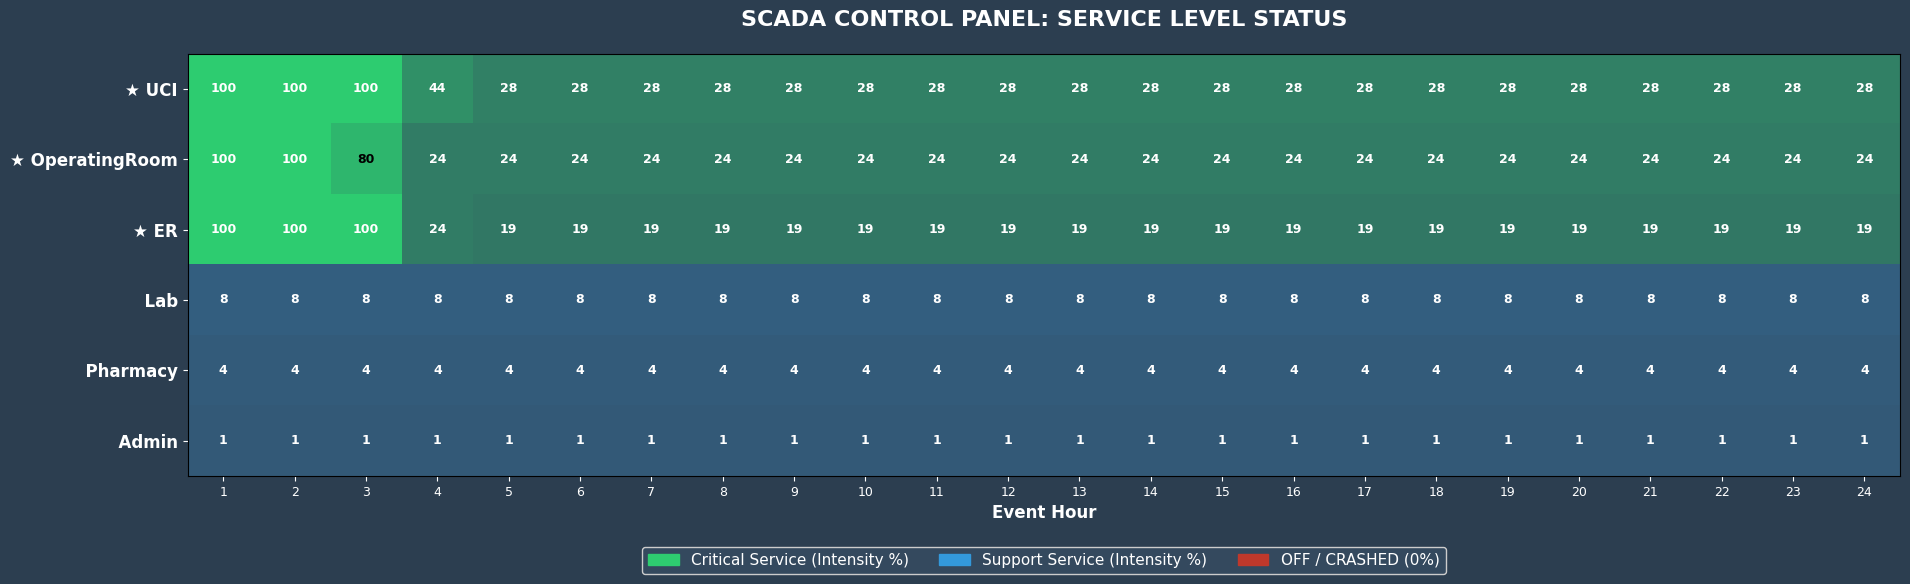

✅ Fuel guardado: graphics\lambda0.5_24hours_budget20000_fuel.png


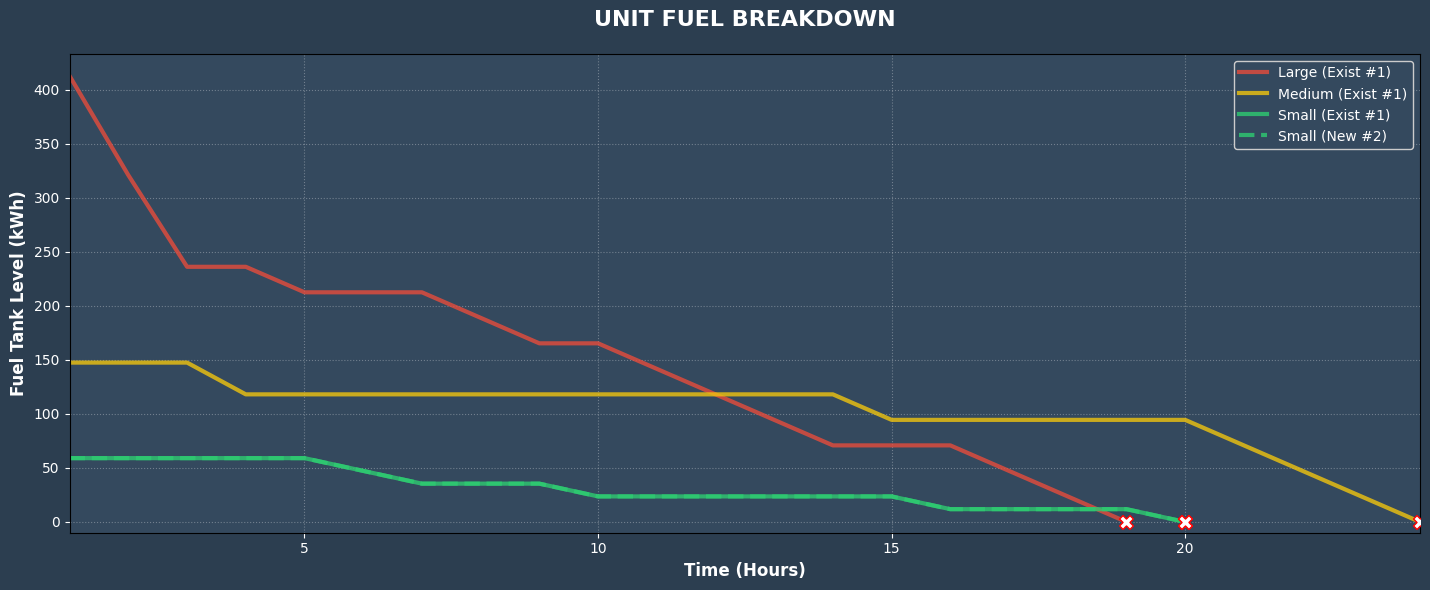

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import numpy as np
import pyomo.environ as pe
import os

plt.style.use('seaborn-v0_8-dark-palette')
plt.rcParams['figure.facecolor'] = '#2c3e50'
plt.rcParams['axes.facecolor'] = '#34495e'
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'

folder_name = "graphics"
if not os.path.exists(folder_name):
    os.makedirs(folder_name)

try:
    val_lambda = round(pe.value(model.lam1), 2)
    val_budget = int(pe.value(model.budget))
    val_hours = len(model.T)
    base_name = f"lambda{val_lambda}_{val_hours}hours_budget{val_budget}"
except:
    base_name = "simulation_results"

print(f"📁 Guardando gráficos con base: {base_name}")

hours = list(model.T)

fig1, ax1 = plt.subplots(figsize=(19.2, 6)) 

y_labels = []
for s in model.S:
    prefix = "★ " if s in model.S_crit else "  "
    y_labels.append(f"{prefix}{s}")

rows = len(y_labels)
cols = len(hours)
rgba_matrix = np.zeros((rows, cols, 4))

c_red    = (0.75, 0.22, 0.17)
c_green  = (0.18, 0.80, 0.44)
c_blue   = (0.20, 0.60, 0.86)

row_idx = 0

for s in model.S:
    is_crit = s in model.S_crit
    base_color = c_green if is_crit else c_blue
    
    for t_idx, t in enumerate(model.T):
        val = pe.value(model.x[s,t])
        
        if val < 0.01: 
            rgba_matrix[row_idx, t_idx] = (*c_red, 0.8)
        else:
            alpha = 0.2 + (0.8 * val)
            rgba_matrix[row_idx, t_idx] = (*base_color, alpha)
            
        
        pct_int = int(val * 100)
        txt_color = 'white' if (val < 0.5 or val > 0.9) else 'black'
        
        if cols <= 50:
            label_text = f"{pct_int}" if val > 0.01 else "X"
            ax1.text(t_idx, row_idx, label_text, ha='center', va='center', 
                    fontsize=9, color=txt_color, fontweight='bold')
            
    row_idx += 1

ax1.imshow(rgba_matrix, aspect='auto', interpolation='nearest')

ax1.set_xticks(np.arange(len(hours)))
ax1.set_xticklabels([str(h) for h in hours], fontsize=9)
ax1.set_yticks(np.arange(len(y_labels)))
ax1.set_yticklabels(y_labels, fontsize=12, fontweight='bold')

ax1.set_title('SCADA CONTROL PANEL: SERVICE LEVEL STATUS', fontsize=16, fontweight='bold', pad=20)
ax1.set_xlabel('Event Hour', fontsize=12, fontweight='bold')
ax1.grid(False)

patches = [
    mpatches.Patch(color=c_green, label='Critical Service (Intensity %)'),
    mpatches.Patch(color=c_blue, label='Support Service (Intensity %)'),
    mpatches.Patch(color=c_red, label='OFF / CRASHED (0%)')
]
ax1.legend(handles=patches, loc='upper center', bbox_to_anchor=(0.5, -0.15), 
          ncol=3, facecolor='#34495e', framealpha=1, fontsize=11)

plt.tight_layout()

filename1 = f"{base_name}_scada.png"
save_path1 = os.path.join(folder_name, filename1)
plt.savefig(save_path1, dpi=300, bbox_inches='tight')
print(f"✅ SCADA guardado: {save_path1}")
plt.show()

colores_base = {'Large': '#e74c3c', 'Medium': '#f1c40f', 'Small': '#2ecc71'}
unit_states = []
max_active_hour = 1

for g in model.G:
    n_exist = int(model.N_exist[g])
    n_new = int(pe.value(model.z_inv[g]))
    total_units = n_exist + n_new

    if total_units == 0: continue

    for i in range(total_units):
        is_new = i >= n_exist
        label = f"{g} ({'New' if is_new else 'Exist'} #{i+1})"
        cap = model.E_max[g] if is_new else model.E_initial[g]
        style = '--' if is_new else '-'
        
        unit_states.append({
            'label': label,
            'g_type': g, 
            'current': cap,
            'history': [],
            'color': colores_base.get(g, 'white'),
            'style': style,
            'depleted_at': None
        })

for t_idx, t in enumerate(model.T):
    
    model_data = {
        g: {
            'u': pe.value(model.u[g,t]), 
            'a': int(pe.value(model.a[g,t]))
        } for g in model.G
    }

    for g in model.G:
        total_gen = model_data[g]['u']
        
        my_units = [u for u in unit_states if u['g_type'] == g]
        
        alive_units = [u for u in my_units if u['current'] > 0.01]
        n_alive = len(alive_units)
        
        if n_alive > 0 and total_gen > 0:
            
            fuel_share = total_gen / n_alive
            
            for unit in alive_units:
                unit['current'] -= fuel_share
                max_active_hour = t
        
    for unit in unit_states:
        if unit['current'] <= 0.01:
            unit['current'] = 0
            if unit['depleted_at'] is None and len(unit['history']) > 0 and unit['history'][-1] > 0:
                unit['depleted_at'] = t
        
        unit['history'].append(unit['current'])

display_limit = min(max(hours), max_active_hour + 2)
calc_width = max(10, display_limit * 0.6) 
calc_width = min(calc_width, 24)

fig2 = plt.figure(figsize=(calc_width, 6)) 
gs = gridspec.GridSpec(1, 1)
ax2 = fig2.add_subplot(gs[0])

for unit in unit_states:
    if unit['depleted_at']:
        end_idx = hours.index(unit['depleted_at']) + 1
        end_idx = min(end_idx, len(hours))
        y_data = unit['history'][:end_idx]
        x_data = hours[:end_idx]
    else:
        y_data = unit['history']
        x_data = hours

    ax2.plot(x_data, y_data, label=unit['label'], color=unit['color'], linestyle=unit['style'], linewidth=3, alpha=0.8)
    
    if unit['depleted_at']:
        ax2.scatter(unit['depleted_at'], 0, marker='X', color='white', edgecolor='red', s=100, zorder=10)
    else:
        final_val = y_data[-1]
        if hours.index(x_data[-1]) < display_limit:
             ax2.text(x_data[-1], final_val, f"{int(final_val)}", va='bottom', ha='right', fontsize=10, color='white', fontweight='bold')

ax2.set_title(f'UNIT FUEL BREAKDOWN', fontsize=16, fontweight='bold', pad=20)
ax2.set_ylabel('Fuel Tank Level (kWh)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Time (Hours)', fontsize=12, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.3, color='white')
ax2.set_xlim(1, display_limit)
ax2.set_ylim(bottom=-10) 
ax2.legend(facecolor='#34495e', framealpha=1, fontsize=10, loc='upper right')

plt.tight_layout()

filename2 = f"{base_name}_fuel.png"
save_path2 = os.path.join(folder_name, filename2)
plt.savefig(save_path2, dpi=300, bbox_inches='tight')
print(f"✅ Fuel guardado: {save_path2}")
plt.show()